# 红酒数据集决策树分类

**任务**：使用 13 个化学特征，把红酒样本分为 3 个品种（`target` = 0/1/2）。

本 Notebook 按实验要求完成：

1. 读取数据，确定特征与预测目标；
2. 固定随机种子，分层划分训练集和测试集；
3. 用 `Pipeline` 构建决策树分类模型并训练；
4. 在测试集上评估模型，并解释评估结果；
5. 可视化决策树，并简要解读。


In [3]:
# %matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42


## 1. 读取数据，确定特征与目标

数据集来自 UCI Wine：178 个酒样、13 个数值型化学特征，目标 `target` 为三个葡萄品种类别。


In [4]:
df = pd.read_csv("wine.csv")

print("数据形状:", df.shape)
print("缺失值数量:", int(df.isna().sum().sum()))
print("重复行数量:", int(df.duplicated().sum()))
print("\ntarget 分布:")
print(df["target"].value_counts().sort_index().to_string())

display(df.head())
display(df.describe().T)


数据形状: (178, 14)
缺失值数量: 0
重复行数量: 0

target 分布:
target
0    59
1    71
2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### 类别分布

三个类别的样本数分别为 59、71、48，存在一定的不均衡。因此后面划分数据时使用 `stratify=y`，保证训练集和测试集的类别比例与原始数据一致。


FileNotFoundError: [Errno 2] No such file or directory: 'images/wine_class_distribution.png'

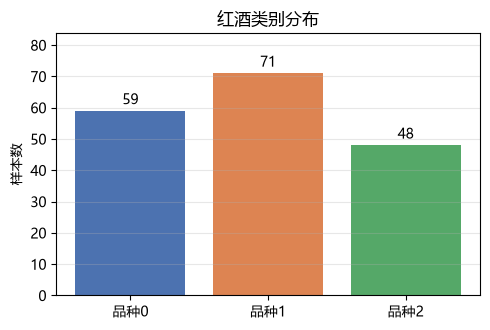

In [5]:
class_counts = df["target"].value_counts().sort_index()
class_labels = ["品种0", "品种1", "品种2"]

fig, ax = plt.subplots(figsize=(5, 3.4))
bars = ax.bar(
    class_labels,
    class_counts.values,
    color=["#4C72B0", "#DD8452", "#55A868"],
)
for bar, count in zip(bars, class_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 1,
        str(count),
        ha="center",
        va="bottom",
    )
ax.set_title("红酒类别分布")
ax.set_ylabel("样本数")
ax.set_ylim(0, class_counts.max() * 1.18)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("images/wine_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 2. 特征、目标与数据划分

- 特征矩阵 `X`：除 `target` 外的 13 列化学指标；
- 目标向量 `y`：`target`，取值 0、1、2。

固定 `random_state=42`，按 7:3 划分训练集和测试集，并使用分层抽样。最终训练集 124 条、测试集 54 条。


In [ ]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("训练集:", X_train.shape)
print("测试集:", X_test.shape)
print("训练集类别:", y_train.value_counts().sort_index().to_dict())
print("测试集类别:", y_test.value_counts().sort_index().to_dict())


训练集: (124, 13)
测试集: (54, 13)
训练集类别: {0: 41, 1: 50, 2: 33}
测试集类别: {0: 18, 1: 21, 2: 15}


## 3. 用 Pipeline 构建决策树模型

决策树按“特征阈值”分裂，对特征量纲不敏感，因此 Pipeline 中不需要标准化步骤，只封装决策树分类器。

为了让树保持可读，预先限制 `max_depth=3`。在训练集上用 5 折分层交叉验证比较 `gini` 和 `entropy` 两种分裂准则；测试集不参与模型选择。


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_scores = {}
for criterion in ["gini", "entropy"]:
    candidate = Pipeline([
        ("tree", DecisionTreeClassifier(
            max_depth=3,
            criterion=criterion,
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
    )
    cv_scores[criterion] = scores
    print(f"{criterion:<8} 5折准确率: {scores.mean():.4f} ± {scores.std():.4f}")


gini     5折准确率: 0.8950 ± 0.0412
entropy  5折准确率: 0.8710 ± 0.0156


交叉验证结果显示 `gini` 略优于 `entropy`（0.8950 对 0.8710），且 gini 是 scikit-learn 的默认准则，因此最终选用：

```python
DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)
```


In [ ]:
model = Pipeline([
    ("tree", DecisionTreeClassifier(
        max_depth=3,
        criterion="gini",
        random_state=RANDOM_STATE,
    )),
])

model.fit(X_train, y_train)
print("训练集准确率:", round(model.score(X_train, y_train), 4))


训练集准确率: 0.9919


## 4. 测试集评估

测试集共 54 条样本。分类问题不能只看准确率，还要看每一类的精确率、召回率和 F1，因此同时输出分类报告和混淆矩阵。


In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro")
recall_macro = recall_score(y_test, y_pred, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print(f"准确率 Accuracy      : {accuracy:.4f}  ({int(round(accuracy * len(y_test)))}/{len(y_test)})")
print(f"宏平均 Precision     : {precision_macro:.4f}")
print(f"宏平均 Recall        : {recall_macro:.4f}")
print(f"宏平均 F1            : {f1_macro:.4f}")
print(f"加权平均 F1           : {f1_weighted:.4f}")
print("\n分类报告:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["品种0", "品种1", "品种2"],
    digits=4,
))


准确率 Accuracy      : 0.9630  (52/54)
宏平均 Precision     : 0.9710
宏平均 Recall        : 0.9593
宏平均 F1            : 0.9638
加权平均 F1           : 0.9632

分类报告:
              precision    recall  f1-score   support

         品种0     1.0000    0.9444    0.9714        18
         品种1     0.9130    1.0000    0.9545        21
         品种2     1.0000    0.9333    0.9655        15

    accuracy                         0.9630        54
   macro avg     0.9710    0.9593    0.9638        54
weighted avg     0.9662    0.9630    0.9632        54



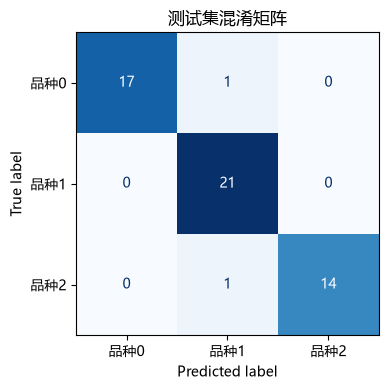

In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["品种0", "品种1", "品种2"],
)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("测试集混淆矩阵")
fig.tight_layout()
fig.savefig("images/wine_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


### 评估结果解释

- 测试集准确率为 **0.9630**，即 54 个样本中 52 个预测正确。
- 宏平均 F1 为 **0.9638**，加权平均 F1 为 **0.9632**，三个类别的整体识别效果较均衡。
- 混淆矩阵中，品种 0 有 17 个正确、1 个被误判为品种 1；品种 1 的 21 个样本全部正确；品种 2 有 14 个正确、1 个被误判为品种 1。
- 品种 1 的召回率为 1.0，但精确率为 0.9130，因为品种 0 和品种 2 各有 1 个样本被误判为品种 1。
- 测试集只有 54 条样本，单个样本对应约 1.85 个百分点；训练集 5 折交叉验证准确率为 **0.8950 ± 0.0412**，可作为更稳定的泛化估计。


## 5. 决策树可视化与解读

为了在图上直接读懂规则，绘图时将英文特征名映射为中文，但模型训练仍使用原始列名。


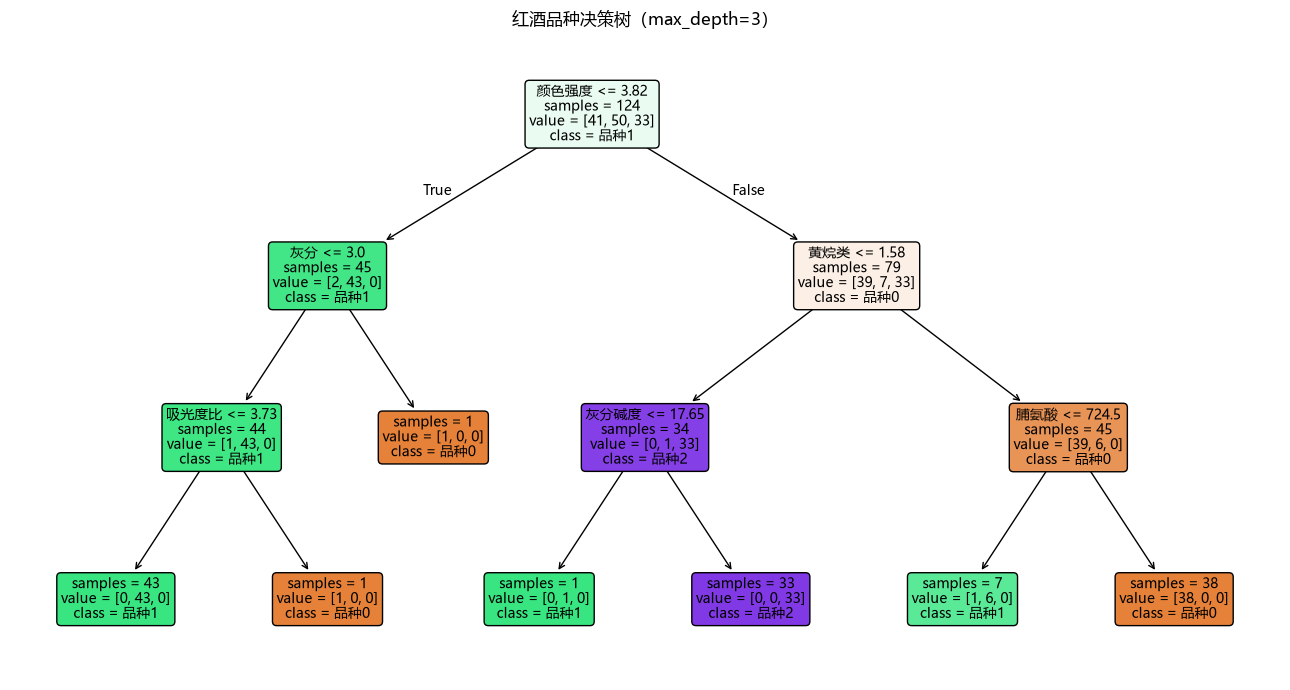

In [ ]:
feature_names_cn = {
    "alcohol": "酒精含量",
    "malic_acid": "苹果酸",
    "ash": "灰分",
    "alcalinity_of_ash": "灰分碱度",
    "magnesium": "镁",
    "total_phenols": "总酚",
    "flavanoids": "黄烷类",
    "nonflavanoid_phenols": "非黄烷类酚",
    "proanthocyanins": "原花青素",
    "color_intensity": "颜色强度",
    "hue": "色调",
    "od280/od315_of_diluted_wines": "吸光度比",
    "proline": "脯氨酸",
}

display_names = [feature_names_cn[c] for c in X.columns]

fig, ax = plt.subplots(figsize=(13, 7))
plot_tree(
    model.named_steps["tree"],
    feature_names=display_names,
    class_names=["品种0", "品种1", "品种2"],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
    ax=ax,
)
ax.set_title("红酒品种决策树（max_depth=3）")
fig.tight_layout()
fig.savefig("images/wine_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
print(export_text(
    model.named_steps["tree"],
    feature_names=display_names,
    decimals=3,
))


|--- 颜色强度 <= 3.820
|   |--- 灰分 <= 3.000
|   |   |--- 吸光度比 <= 3.730
|   |   |   |--- class: 1
|   |   |--- 吸光度比 >  3.730
|   |   |   |--- class: 0
|   |--- 灰分 >  3.000
|   |   |--- class: 0
|--- 颜色强度 >  3.820
|   |--- 黄烷类 <= 1.580
|   |   |--- 灰分碱度 <= 17.650
|   |   |   |--- class: 1
|   |   |--- 灰分碱度 >  17.650
|   |   |   |--- class: 2
|   |--- 黄烷类 >  1.580
|   |   |--- 脯氨酸 <= 724.500
|   |   |   |--- class: 1
|   |   |--- 脯氨酸 >  724.500
|   |   |   |--- class: 0



### 树结构解读

根节点先按 **颜色强度 ≤ 3.820** 划分：

- 左分支（颜色强度较低）：再看灰分；灰分 ≤ 3.0 时，继续用吸光度比区分品种 1 和品种 0；灰分 > 3.0 时直接判为品种 0。
- 右分支（颜色强度较高）：先看黄烷类；黄烷类 ≤ 1.58 时，用灰分碱度区分品种 1 和品种 2；黄烷类 > 1.58 时，再用脯氨酸区分品种 1 和品种 0。

这说明颜色强度、黄烷类、脯氨酸和灰分相关指标是区分三个品种的主要依据。树的最大深度为 3，共有 7 个叶子节点，规则数量少，便于解释；但数据集只有 178 条样本，阈值对训练样本较敏感，不能把某个具体数值当成绝对的生物学界限。


非零特征重要性:
黄烷类     0.413615
颜色强度    0.405286
脯氨酸     0.108863
吸光度比    0.024497
灰分碱度    0.024330
灰分      0.023409


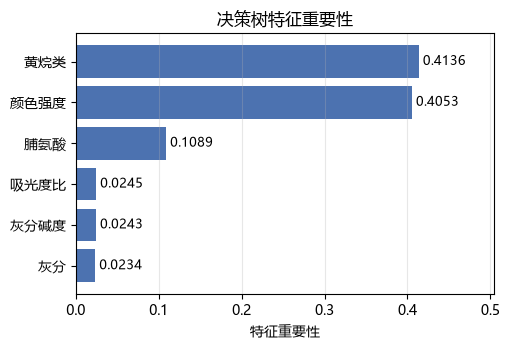

In [ ]:
importances = pd.Series(
    model.named_steps["tree"].feature_importances_,
    index=display_names,
).sort_values(ascending=False)

print("非零特征重要性:")
print(importances[importances > 0].to_string())

nonzero = importances[importances > 0].sort_values()
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.barh(nonzero.index, nonzero.values, color="#4C72B0")
for y_pos, value in enumerate(nonzero.values):
    ax.text(value + 0.005, y_pos, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlabel("特征重要性")
ax.set_title("决策树特征重要性")
ax.set_xlim(0, nonzero.max() * 1.22)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("images/wine_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


### 特征重要性

特征重要性由节点分裂带来的基尼下降加权得到：

- 黄烷类：0.4136
- 颜色强度：0.4053
- 脯氨酸：0.1089
- 吸光度比、灰分碱度、灰分：各约 0.02

黄烷类和颜色强度合计贡献约 82% 的重要性，是最主要的判别特征；脯氨酸主要帮助区分品种 0 和品种 1。其余 7 个特征在当前深度的树中没有参与分裂，重要性为 0。

## 6. 结论与改进方向

本实验完成了数据读取、固定随机种子分层划分、Pipeline 决策树训练、测试集评估和决策树可视化。最终模型测试准确率为 0.9630，宏平均 F1 为 0.9638；决策树深度限制为 3，结构清晰，可以直接读出分类规则。

改进方向：

1. 数据量只有 178 条，建议使用重复分层交叉验证或留一法，让评估结果更稳定；
2. 可在训练集上调整 `max_depth`、`min_samples_leaf`、`ccp_alpha` 等参数，并用交叉验证选择，而不是用测试集调参；
3. 决策树对数据扰动较敏感，可尝试随机森林或梯度提升树提升准确率和稳定性；
4. 三个类别存在一定不均衡，后续可同时报告宏平均指标和每类召回率，避免只看总体准确率。
